<a href="https://colab.research.google.com/github/mohammad-mustafa130/Alzheimers-MRI-Classification/blob/main/Alzheimers_MRI_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import sys
import os

print("Alzheimer MRI Classification Project")
print("------------------------------------")

print("Python Version:", sys.version)
print("Current Directory:", os.getcwd())

# Check TensorFlow installation
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

# Check GPU availability
print("Available GPU:", tf.config.list_physical_devices('GPU'))


Alzheimer MRI Classification Project
------------------------------------
Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Current Directory: /content
TensorFlow Version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:

from google.colab import drive

# Connect Google Drive with Colab
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:

import os

dataset_folder = "/content/drive/MyDrive/Alzheimers_MRI_Project/dataset"

print("Files inside dataset folder:")

for file in os.listdir(dataset_folder):
    print(file)


Files inside dataset folder:
Alzheimer (Preprocessed Data).zip


In [10]:

import zipfile
import os

zip_path = os.path.join(
    dataset_folder,
    "Alzheimer (Preprocessed Data).zip"
)

extract_path = "/content/alzheimers_dataset"

# Extract dataset
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Extraction location:", extract_path)


Dataset extracted successfully!
Extraction location: /content/alzheimers_dataset


In [11]:
import os

dataset_path = "/content/alzheimers_dataset"

print("DATASET FOLDER STRUCTURE")
print("========================")

# Check whether the extraction folder exists
print("Folder exists:", os.path.exists(dataset_path))

# Display files and folders
print("\nContents of extraction folder:")

for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)

    if os.path.isdir(item_path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)

DATASET FOLDER STRUCTURE
Folder exists: True

Contents of extraction folder:
📁 Folder: Alzheimer (Preprocessed Data)


In [12]:
import os

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

print("INSIDE ALZHEIMER DATASET")
print("========================")

for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)

    if os.path.isdir(item_path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)

INSIDE ALZHEIMER DATASET
📁 Folder: Moderate_Demented
📁 Folder: Non_Demented
📁 Folder: Very_Mild_Demented
📁 Folder: Mild_Demented


In [13]:
import os

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

print("NUMBER OF IMAGES IN EACH CLASS")
print("--------------------------------")

total_images = 0

for class_name in os.listdir(dataset_path):

    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):

        images = os.listdir(class_path)

        image_count = len(images)

        total_images += image_count

        print(class_name, ":", image_count)

print("--------------------------------")
print("Total Images:", total_images)

NUMBER OF IMAGES IN EACH CLASS
--------------------------------
Moderate_Demented : 64
Non_Demented : 3200
Very_Mild_Demented : 2240
Mild_Demented : 896
--------------------------------
Total Images: 6400


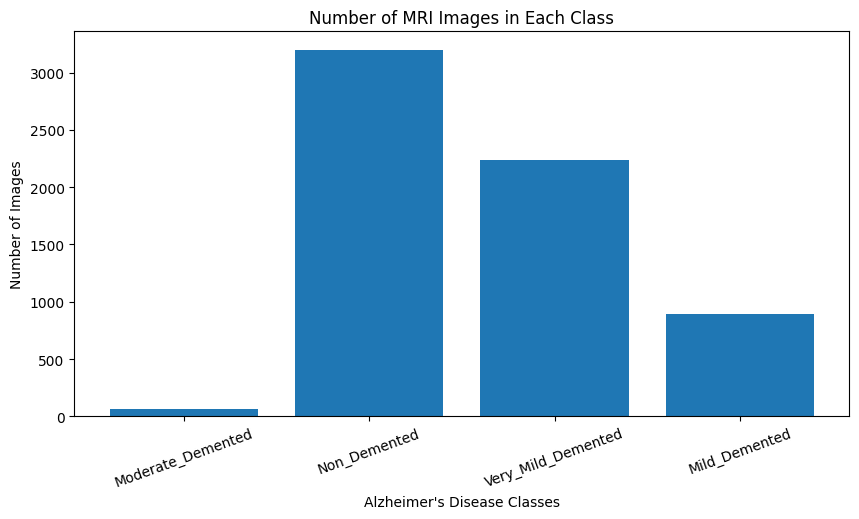

In [14]:
import os
import matplotlib.pyplot as plt

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

class_names = []
image_counts = []

for class_name in os.listdir(dataset_path):

    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):

        count = len(os.listdir(class_path))

        class_names.append(class_name)
        image_counts.append(count)

# Create bar chart
plt.figure(figsize=(10, 5))

plt.bar(class_names, image_counts)

plt.title("Number of MRI Images in Each Class")
plt.xlabel("Alzheimer's Disease Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=20)
plt.show()

In [15]:
import os
import numpy as np
from PIL import Image

dataset_path = "/content/alzheimers_dataset/Alzheimer (Preprocessed Data)"

class_names = [
    "Non_Demented",
    "Very_Mild_Demented",
    "Mild_Demented",
    "Moderate_Demented"
]

print("MRI PIXEL VALUE INSPECTION")
print("==========================")

for class_name in class_names:

    class_path = os.path.join(dataset_path, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    image_path = os.path.join(class_path, image_files[0])

    image = Image.open(image_path)

    image_array = np.array(image)

    print("\nClass:", class_name)
    print("Image shape:", image_array.shape)
    print("Data type:", image_array.dtype)
    print("Minimum pixel value:", np.min(image_array))
    print("Maximum pixel value:", np.max(image_array))
    print("Average pixel value:", np.mean(image_array))

MRI PIXEL VALUE INSPECTION

Class: Non_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Average pixel value: 79.02581787109375

Class: Very_Mild_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 251
Average pixel value: 56.57513427734375

Class: Mild_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 254
Average pixel value: 66.76220703125

Class: Moderate_Demented
Image shape: (128, 128)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 249
Average pixel value: 68.45330810546875


In [16]:
import os
import numpy as np
from PIL import Image

# Select the Non_Demented class
class_path = os.path.join(dataset_path, "Non_Demented")

# Get the first image filename
image_name = os.listdir(class_path)[0]

# Create the complete image path
image_path = os.path.join(class_path, image_name)

# Open the MRI image
image = Image.open(image_path)

# Convert image into a NumPy array
image_array = np.array(image)

# Normalize pixel values
normalized_image = image_array.astype("float32") / 255.0

# Compare original and normalized images
print("BEFORE NORMALIZATION")
print("Data type:", image_array.dtype)
print("Minimum:", image_array.min())
print("Maximum:", image_array.max())

print("\nAFTER NORMALIZATION")
print("Data type:", normalized_image.dtype)
print("Minimum:", normalized_image.min())
print("Maximum:", normalized_image.max())

print("\nFirst 10 original pixel values:")
print(image_array[64, :10])

print("\nFirst 10 normalized pixel values:")
print(normalized_image[64, :10])

BEFORE NORMALIZATION
Data type: uint8
Minimum: 0
Maximum: 255

AFTER NORMALIZATION
Data type: float32
Minimum: 0.0
Maximum: 1.0

First 10 original pixel values:
[0 0 0 0 0 0 0 0 0 0]

First 10 normalized pixel values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
